In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
# If you opened this notebook from the notebooks/ folder, move up to the project root.
if not (PROJECT_ROOT / "data" / "processed").exists() and (PROJECT_ROOT.parent / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "transactions_features.csv.gz"
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "outputs"
SPLIT_CONFIG_PATH = OUTPUT_DIR / "split_config.json"
SPLIT_REPORT_PATH = OUTPUT_DIR / "imbalance_split_report.csv"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Feature dataset exists:", DATA_PATH.exists())
print("Feature dataset path:", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not find transactions_features.csv.gz. Confirm Notebook 03 saved it under "
        "data/processed/transactions_features.csv.gz."
    )

Project root: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system
Feature dataset exists: True
Feature dataset path: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\data\processed\transactions_features.csv.gz


In [2]:
# Load the engineered dataset. This dataset is large, so allow time for this cell to finish.
df = pd.read_csv(DATA_PATH, compression="gzip")

TARGET = "isFraud"
TIME_COL = "step"

required = {TARGET, TIME_COL}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Required columns are missing: {missing}")

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print("Target counts:")
display(df[TARGET].value_counts(dropna=False).rename_axis("isFraud").to_frame("rows"))

print("Step range:", int(df[TIME_COL].min()), "to", int(df[TIME_COL].max()))
print("Unique steps:", int(df[TIME_COL].nunique()))

Rows: 6,362,620
Columns: 22
Target counts:


,rows
isFraud,
0,6354407
1,8213


Step range: 1 to 743
Unique steps: 743


In [3]:
# Calculate the imbalance ratio and fraud percentage.
class_counts = df[TARGET].value_counts().sort_index()
normal_count = int(class_counts.get(0, 0))
fraud_count = int(class_counts.get(1, 0))
total_count = normal_count + fraud_count

fraud_pct = (fraud_count / total_count * 100) if total_count else 0
normal_to_fraud_ratio = (normal_count / fraud_count) if fraud_count else np.inf

imbalance_summary = pd.DataFrame({
    "metric": [
        "total_rows",
        "normal_rows",
        "fraud_rows",
        "fraud_percentage",
        "normal_to_fraud_ratio"
    ],
    "value": [
        total_count,
        normal_count,
        fraud_count,
        fraud_pct,
        normal_to_fraud_ratio
    ]
})

display(imbalance_summary)
print(f"Fraud prevalence: {fraud_pct:.4f}%")
print(f"Approximate class ratio: 1 fraud to {normal_to_fraud_ratio:,.1f} normal transactions")

,metric,value
0,total_rows,6.362620e+06
1,normal_rows,6.354407e+06
2,fraud_rows,8.213000e+03
3,fraud_percentage,1.290820e-01
4,normal_to_fraud_ratio,7.737011e+02


Fraud prevalence: 0.1291%
Approximate class ratio: 1 fraud to 773.7 normal transactions


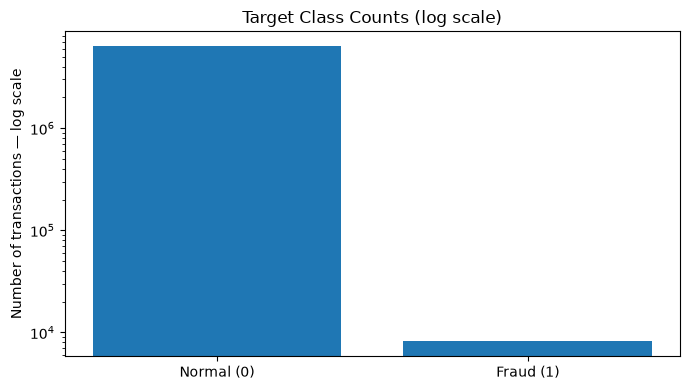

In [4]:
# Visualize the imbalance on a log scale so both classes remain visible.
counts_for_plot = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
plt.figure(figsize=(7, 4))
plt.bar(["Normal (0)", "Fraud (1)"], counts_for_plot.values)
plt.yscale("log")
plt.title("Target Class Counts (log scale)")
plt.ylabel("Number of transactions — log scale")
plt.tight_layout()
plt.show()

## Choose a chronological holdout

We use the earliest **80% of distinct `step` values** for training and the latest **20% of distinct `step` values** for testing. The split is based on time steps, not a random row split.


In [5]:
unique_steps = np.sort(df[TIME_COL].dropna().unique())
if len(unique_steps) < 2:
    raise ValueError("At least two distinct step values are required for a chronological split.")

cutoff_position = int(np.floor(len(unique_steps) * 0.80)) - 1
cutoff_position = max(0, min(cutoff_position, len(unique_steps) - 2))
cutoff_step = int(unique_steps[cutoff_position])

train_mask = df[TIME_COL] <= cutoff_step
test_mask = df[TIME_COL] > cutoff_step

train_rows = int(train_mask.sum())
test_rows = int(test_mask.sum())

if train_rows == 0 or test_rows == 0:
    raise ValueError("Chronological split produced an empty train or test set.")

print("Number of unique steps:", len(unique_steps))
print("Training uses step <=", cutoff_step)
print("Testing uses step >", cutoff_step)
print(f"Training rows: {train_rows:,} ({train_rows / len(df) * 100:.2f}%)")
print(f"Testing rows:  {test_rows:,} ({test_rows / len(df) * 100:.2f}%)")
print("Train step range:", int(df.loc[train_mask, TIME_COL].min()), "to", int(df.loc[train_mask, TIME_COL].max()))
print("Test step range:", int(df.loc[test_mask, TIME_COL].min()), "to", int(df.loc[test_mask, TIME_COL].max()))

assert df.loc[train_mask, TIME_COL].max() < df.loc[test_mask, TIME_COL].min()
print("Chronological split check: PASSED")

Number of unique steps: 743
Training uses step <= 594
Testing uses step > 594
Training rows: 6,239,040 (98.06%)
Testing rows:  123,580 (1.94%)
Train step range: 1 to 594
Test step range: 595 to 743
Chronological split check: PASSED


In [6]:
# Compare target prevalence in each partition.
def target_stats(partition_name, subset):
    counts = subset[TARGET].value_counts()
    n_normal = int(counts.get(0, 0))
    n_fraud = int(counts.get(1, 0))
    n_total = len(subset)
    return {
        "partition": partition_name,
        "rows": n_total,
        "normal_rows": n_normal,
        "fraud_rows": n_fraud,
        "fraud_percentage": (n_fraud / n_total * 100) if n_total else 0,
        "min_step": int(subset[TIME_COL].min()),
        "max_step": int(subset[TIME_COL].max())
    }

split_report = pd.DataFrame([
    target_stats("all_data", df),
    target_stats("train", df.loc[train_mask]),
    target_stats("test", df.loc[test_mask])
])

display(split_report)

,partition,rows,normal_rows,fraud_rows,fraud_percentage,min_step,max_step
0,all_data,6362620,6354407,8213,0.129082,1,743
1,train,6239040,6232481,6559,0.105128,1,594
2,test,123580,121926,1654,1.338404,595,743


## Save the split configuration (without duplicating the large dataset)




In [9]:
split_config = {
    "dataset_path": "data/processed/transactions_features.csv.gz",
    "target_column": TARGET,
    "time_column": TIME_COL,
    "split_method": "chronological_by_step",
    "train_rule": f"{TIME_COL} <= {cutoff_step}",
    "test_rule": f"{TIME_COL} > {cutoff_step}",
    "cutoff_step": cutoff_step,
    "train_step_min": int(df.loc[train_mask, TIME_COL].min()),
    "train_step_max": int(df.loc[train_mask, TIME_COL].max()),
    "test_step_min": int(df.loc[test_mask, TIME_COL].min()),
    "test_step_max": int(df.loc[test_mask, TIME_COL].max()),
    "train_rows": train_rows,
    "test_rows": test_rows,
    "random_split": False,
    "resampling_applied": False,
    "exclude_from_initial_features": ["isFraud", "isFlaggedFraud", "nameOrig", "nameDest"]
}

with open(SPLIT_CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(split_config, f, indent=2)

split_report.to_csv(SPLIT_REPORT_PATH, index=False)

print("Saved split configuration:", SPLIT_CONFIG_PATH)
print("Saved split report:", SPLIT_REPORT_PATH)
print("Configuration:")
print(json.dumps(split_config, indent=2))

Saved split configuration: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\split_config.json
Saved split report: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\imbalance_split_report.csv
Configuration:
{
  "dataset_path": "data/processed/transactions_features.csv.gz",
  "target_column": "isFraud",
  "time_column": "step",
  "split_method": "chronological_by_step",
  "train_rule": "step <= 594",
  "test_rule": "step > 594",
  "cutoff_step": 594,
  "train_step_min": 1,
  "train_step_max": 594,
  "test_step_min": 595,
  "test_step_max": 743,
  "train_rows": 6239040,
  "test_rows": 123580,
  "random_split": false,
  "resampling_applied": false,
  "exclude_from_initial_features": [
    "isFraud",
    "isFlaggedFraud",
    "nameOrig",
    "nameDest"
  ]
}


In [10]:
# Final checks for this notebook.
assert int(df[TARGET].sum()) == fraud_count
assert train_rows + test_rows == len(df)
assert int(df.loc[train_mask, TIME_COL].max()) < int(df.loc[test_mask, TIME_COL].min())
assert not split_config["resampling_applied"]

print("NOTEBOOK 04 — CLASS IMBALANCE AND SPLITTING SUMMARY")
print("-" * 55)
print(f"Rows: {len(df):,}")
print(f"Fraud rows: {fraud_count:,}")
print(f"Normal rows: {normal_count:,}")
print(f"Fraud percentage: {fraud_pct:.4f}%")
print(f"Normal:fraud ratio: {normal_to_fraud_ratio:,.1f}:1")
print(f"Train rows: {train_rows:,}")
print(f"Test rows: {test_rows:,}")
print(f"Chronological cutoff: step {cutoff_step}")
print("Resampling applied: No")
print("Split configuration saved:", SPLIT_CONFIG_PATH.exists())
print("Split report saved:", SPLIT_REPORT_PATH.exists())
print("All validation checks passed.")

NOTEBOOK 04 — CLASS IMBALANCE AND SPLITTING SUMMARY
-------------------------------------------------------
Rows: 6,362,620
Fraud rows: 8,213
Normal rows: 6,354,407
Fraud percentage: 0.1291%
Normal:fraud ratio: 773.7:1
Train rows: 6,239,040
Test rows: 123,580
Chronological cutoff: step 594
Resampling applied: No
Split configuration saved: True
Split report saved: True
All validation checks passed.
